# 13 — Máxima Verossimilhança

No notebook 08, o método `.fit` "escolheu" a média e o desvio de uma normal para as contas. No ML-01, a regressão linear escolheu coeficientes minimizando o **erro quadrático**; no ML-02, a regressão logística minimizou a **log loss**. De onde vêm essas escolhas? Por que não o erro absoluto, ou outra coisa?

Por trás de todas elas há um único princípio: a **máxima verossimilhança**. Escolha os parâmetros que tornam os dados observados **o mais prováveis possível**.

Neste notebook vamos:
- Definir a **verossimilhança** e a **log-verossimilhança**
- Encontrar o estimador de máxima verossimilhança (**EMV**) para a binomial, a normal e a Poisson
- Usar um **otimizador numérico** quando não há fórmula
- Mostrar que **erros normais ⇒ mínimos quadrados** (regressão linear)
- Mostrar que **Bernoulli ⇒ log loss** (regressão logística), construindo uma logística à mão
- Comparar modelos com a log-verossimilhança e o **AIC**

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize           # encontra o mínimo de uma função numericamente
from sklearn.linear_model import LogisticRegression

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: verossimilhança

Até aqui, usamos a probabilidade "para frente": **conhecendo** o parâmetro (uma moeda com $p = 0{,}5$), calculamos a chance dos dados (7 caras em 10).

A **verossimilhança** (*likelihood*) faz a pergunta "ao contrário": **conhecendo os dados** (7 caras em 10), quão compatível é cada valor possível do parâmetro?

$$L(p) = P(\text{dados} \mid p) = \binom{10}{7} p^7 (1-p)^3$$

É a **mesma fórmula** da binomial, mas agora os dados estão fixos e $p$ varia. $L(p)$ **não** é uma probabilidade de $p$ (a área sob a curva nem dá 1); é uma medida de quão bem cada $p$ "explica" os dados.

O **estimador de máxima verossimilhança** (EMV) é o valor do parâmetro que **maximiza** $L$.

Analogia: um detetive com várias suspeitas. Para cada suspeito, ele pergunta "se fosse esse, quão provável seria encontrar exatamente estas pistas?". O suspeito que melhor explica as pistas é o principal.

EMV de p: 0.700   (proporção observada: 0.7)
Área sob L(p): 0.0909   (não é 1: L não é uma distribuição de p)


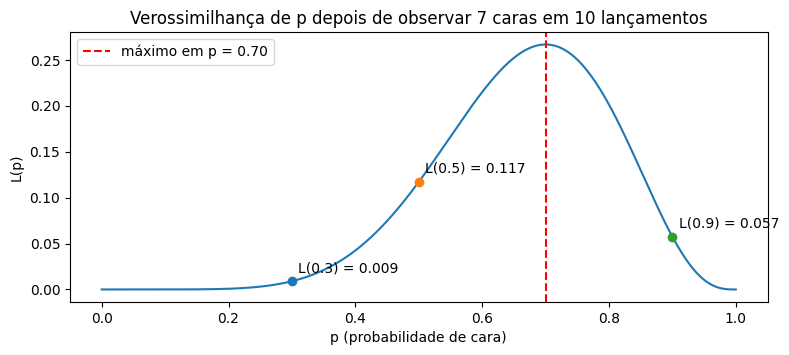

In [2]:
caras, n = 7, 10
p_grade = np.linspace(0, 1, 1001)
verossimilhanca = stats.binom.pmf(caras, n, p_grade)   # a PMF avaliada em cada p, com os dados fixos

p_emv = p_grade[np.argmax(verossimilhanca)]
print(f"EMV de p: {p_emv:.3f}   (proporção observada: {caras / n})")
print(f"Área sob L(p): {np.trapezoid(verossimilhanca, p_grade):.4f}   (não é 1: L não é uma distribuição de p)")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(p_grade, verossimilhanca)
ax.axvline(p_emv, color="red", linestyle="--", label=f"máximo em p = {p_emv:.2f}")
for p_teste in [0.3, 0.5, 0.9]:
    ax.scatter(p_teste, stats.binom.pmf(caras, n, p_teste), zorder=3)
    ax.annotate(f"L({p_teste}) = {stats.binom.pmf(caras, n, p_teste):.3f}", (p_teste + 0.01, stats.binom.pmf(caras, n, p_teste) + 0.01))
ax.set_xlabel("p (probabilidade de cara)")
ax.set_ylabel("L(p)")
ax.set_title("Verossimilhança de p depois de observar 7 caras em 10 lançamentos")
ax.legend()
plt.show()

**Conclusão:** a verossimilhança é máxima em **p = 0,70**, exatamente a proporção de caras observada. Valores como p = 0,5 (L = **0,117**) explicam os dados razoavelmente; p = 0,3 (L = **0,009**) explica muito mal, porque seria muito improvável ver 7 caras com uma moeda que favorece coroa.

A área sob a curva é **0,091**, e não 1: a verossimilhança não é uma distribuição de probabilidade para $p$. Para obter uma distribuição de $p$, é preciso combinar a verossimilhança com uma priori, usando o Teorema de Bayes. É exatamente o que faremos no notebook 16.

## 🎓 Conceito: log-verossimilhança

Com $n$ observações **independentes**, a verossimilhança é o **produto** das probabilidades de cada uma:

$$L(\theta) = \prod_{i=1}^{n} f(x_i \mid \theta)$$

(O $\prod$ é o "produtório", a versão de multiplicação do $\sum$.) Isso cria dois problemas: multiplicar milhares de números pequenos dá um resultado tão minúsculo que o computador arredonda para **zero**; e produtos são difíceis de derivar.

A solução é usar o **logaritmo**, que transforma produtos em **somas** (notebook 03) e não muda onde está o máximo (o log é crescente):

$$\ell(\theta) = \log L(\theta) = \sum_{i=1}^{n} \log f(x_i \mid \theta)$$

Na prática, os otimizadores **minimizam**, então trabalhamos com a **log-verossimilhança negativa** ($-\ell$). Maximizar $\ell$ é o mesmo que minimizar $-\ell$.

In [3]:
# 2.000 lançamentos de uma moeda com p = 0,7: o produto das probabilidades "some" no computador.
n_lanc = 2_000
lancamentos = rng.random(n_lanc) < 0.7
probabilidades_individuais = np.where(lancamentos, 0.7, 0.3)    # P(cada lançamento | p = 0,7)
print(f"Produto das {n_lanc} probabilidades: {np.prod(probabilidades_individuais)}")
print(f"Soma dos logs:                    {np.sum(np.log(probabilidades_individuais)):.2f}")

# A log-verossimilhança de p para esses dados, e o seu máximo.
k = lancamentos.sum()
log_L = k * np.log(p_grade[1:-1]) + (n_lanc - k) * np.log(1 - p_grade[1:-1])   # sem p = 0 e p = 1, onde log(0) = -∞
print(f"\nEMV pela grade: {p_grade[1:-1][np.argmax(log_L)]:.3f}   proporção observada: {k / n_lanc:.4f}")

Produto das 2000 probabilidades: 0.0
Soma dos logs:                    -1236.98

EMV pela grade: 0.691   proporção observada: 0.6910


**Conclusão:** o produto das probabilidades de 2.000 lançamentos deu exatamente **0,0** no computador: o número verdadeiro (cerca de $10^{-537}$) é pequeno demais para ser representado. A soma dos logs (**−1.236,98**) não tem esse problema.

E o máximo da log-verossimilhança continua no lugar certo: **0,691**, a proporção de caras observada (0,6910). A moeda simulada tinha $p = 0{,}7$; o EMV erra um pouco, como qualquer estimativa feita com uma amostra.

## 🎓 Conceito: o EMV da normal e da Poisson

Para algumas distribuições, dá para encontrar o máximo com cálculo (derivando $\ell$ e igualando a zero). Os resultados são intuitivos:

| Distribuição | EMV |
|---|---|
| Bernoulli / binomial | $\hat{p} = $ proporção de sucessos |
| Normal | $\hat{\mu} = \bar{x}$ e $\hat{\sigma} = \sqrt{\frac{1}{n}\sum (x_i - \bar{x})^2}$ (dividindo por $n$!) |
| Poisson | $\hat{\lambda} = \bar{x}$ |
| Exponencial | $\hat{\lambda} = 1 / \bar{x}$ |

Repare no $\hat{\sigma}$ da normal: o EMV divide por $n$, e não por $n - 1$. Ele é **levemente viesado** (notebook 02), mas, com amostras grandes, a diferença some. É por isso que o `.fit` do notebook 08 deu um desvio um pouquinho menor que o `.std()` do pandas.

Quando não há fórmula, usamos um **otimizador numérico**: um algoritmo que "caminha morro abaixo" na função $-\ell$ até o ponto mais baixo. Vamos conferir que ele encontra as fórmulas acima para a massa dos pinguins Adelie.

Otimizador: μ = 3.7062  σ = 0.4570   (convergiu? True)
Fórmulas:   μ = 3.7062  σ = 0.4570   (std com ddof=1: 0.4586)


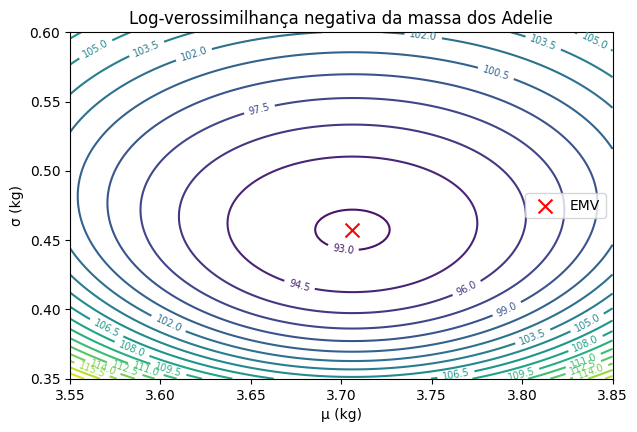

In [4]:
massa = pinguins.loc[pinguins["species"] == "Adelie", "body_mass_g"].to_numpy() / 1000   # em kg

def nll_normal(parametros):
    """Log-verossimilhança negativa de uma normal para a massa dos pinguins."""
    mu, log_sigma = parametros
    sigma = np.exp(log_sigma)   # otimizamos log(σ) para garantir que σ seja sempre positivo
    return -np.sum(stats.norm.logpdf(massa, mu, sigma))   # logpdf = log da densidade, calculado de forma estável


resultado = minimize(nll_normal, x0=[1.0, 0.0])   # x0: o ponto de partida da "caminhada"
mu_emv, sigma_emv = resultado.x[0], np.exp(resultado.x[1])
print(f"Otimizador: μ = {mu_emv:.4f}  σ = {sigma_emv:.4f}   (convergiu? {resultado.success})")
print(f"Fórmulas:   μ = {massa.mean():.4f}  σ = {massa.std(ddof=0):.4f}   (std com ddof=1: {massa.std(ddof=1):.4f})")

# A superfície de -ℓ(μ, σ): o otimizador desceu até o fundo deste "vale".
mus = np.linspace(3.55, 3.85, 150)
sigmas = np.linspace(0.35, 0.6, 150)
M, S = np.meshgrid(mus, sigmas)
superficie = np.array([[nll_normal([m, np.log(s)]) for m in mus] for s in sigmas])

fig, ax = plt.subplots(figsize=(7, 4.5))
contornos = ax.contour(M, S, superficie, levels=20, cmap="viridis")
ax.clabel(contornos, fontsize=7)                       # escreve o valor de -ℓ em algumas curvas
ax.scatter(mu_emv, sigma_emv, color="red", marker="x", s=100, label="EMV")
ax.set_xlabel("μ (kg)")
ax.set_ylabel("σ (kg)")
ax.set_title("Log-verossimilhança negativa da massa dos Adelie")
ax.legend()
plt.show()

In [5]:
# Poisson: o EMV de λ é a média. Conferindo com o otimizador em contagens simuladas.
contagens = rng.poisson(4, size=200)
nll_poisson = lambda lam: -np.sum(stats.poisson.logpmf(contagens, lam[0]))
lam_emv = minimize(nll_poisson, x0=[1.0], bounds=[(0.01, None)]).x[0]   # bounds: λ precisa ser positivo
print(f"Poisson: EMV pelo otimizador = {lam_emv:.4f}   média das contagens = {contagens.mean():.4f}")

Poisson: EMV pelo otimizador = 3.9300   média das contagens = 3.9300


**Conclusão:** o otimizador encontrou exatamente as fórmulas: $\hat{\mu} = 3{,}7062$ kg (a média) e $\hat{\sigma} = 0{,}4570$ kg, o desvio **dividido por $n$** (com $n - 1$ seria 0,4586). No gráfico, as curvas de nível da log-verossimilhança negativa formam um "vale", e o EMV (o X vermelho) está no fundo dele.

Na Poisson, o otimizador e a média das contagens também coincidem (**3,93**). Quando há uma fórmula, ela e o otimizador concordam; quando não há (como na logística, a seguir), o otimizador é o único caminho.

## 🎓 Conceito: erros normais ⇒ mínimos quadrados

A regressão linear supõe que $y = a + b\,x + \varepsilon$, onde o erro $\varepsilon$ é **normal** com média 0 e desvio $\sigma$. Ou seja, cada $y_i$ é normal com média $a + b\,x_i$. A log-verossimilhança é:

$$\ell(a, b) = \sum_i \log f(y_i) = \text{constante} - \frac{1}{2\sigma^2}\sum_i \big(y_i - (a + b\,x_i)\big)^2$$

A única parte que depende de $a$ e $b$ é a **soma dos quadrados dos erros**, com um sinal de menos. Então:

**maximizar a verossimilhança com erros normais = minimizar a soma dos erros ao quadrado.**

É por isso que a regressão linear usa o MSE: ele **é** a verossimilhança da normal disfarçada. (E se supusermos erros com a distribuição de Laplace, que tem caudas mais pesadas, a verossimilhança vira a soma dos erros **absolutos**: o MAE, que no notebook 02 vimos ser minimizado pela mediana.)

In [6]:
x = gorjetas["total_bill"].to_numpy()
y = gorjetas["tip"].to_numpy()

def nll_regressao(parametros):
    a, b, log_sigma = parametros
    return -np.sum(stats.norm.logpdf(y, loc=a + b * x, scale=np.exp(log_sigma)))

a_emv, b_emv, _ = minimize(nll_regressao, x0=[0, 0, 0]).x
# np.polyfit ajusta uma reta (grau 1) pelos mínimos quadrados e devolve [inclinação, intercepto].
b_mq, a_mq = np.polyfit(x, y, deg=1)
print(f"Máxima verossimilhança (normal): gorjeta = {a_emv:.4f} + {b_emv:.4f} × conta")
print(f"Mínimos quadrados (polyfit):     gorjeta = {a_mq:.4f} + {b_mq:.4f} × conta")

Máxima verossimilhança (normal): gorjeta = 0.9203 + 0.1050 × conta
Mínimos quadrados (polyfit):     gorjeta = 0.9203 + 0.1050 × conta


**Conclusão:** as duas retas são **idênticas** até a quarta casa decimal: gorjeta ≈ **0,92 + 0,105 × conta**. Maximizar a verossimilhança com erros normais e minimizar o erro quadrático são o mesmo problema. Na prática, cada dólar a mais na conta vem acompanhado, em média, de cerca de **10,5 centavos** a mais de gorjeta.

Isso também mostra quando o MSE pode ser uma escolha **ruim**: se os erros tiverem caudas pesadas (muitos outliers), a suposição de normalidade não vale, e a verossimilhança "certa" seria outra.

## 🎓 Conceito: Bernoulli ⇒ log loss (a regressão logística)

Na classificação binária, cada $y_i$ é 0 ou 1: uma **Bernoulli** com probabilidade $p_i$. A regressão logística modela essa probabilidade com a função **sigmoide**:

$$p_i = \frac{1}{1 + e^{-(a + b\,x_i)}}$$

A probabilidade de observar $y_i$ é $p_i$ se $y_i = 1$ e $1 - p_i$ se $y_i = 0$, o que pode ser escrito numa linha só: $p_i^{y_i}(1-p_i)^{1-y_i}$. A log-verossimilhança é:

$$\ell(a, b) = \sum_i \Big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big]$$

E a **log loss** do ML-02 é exatamente $-\ell / n$: a log-verossimilhança negativa **média**. Treinar uma regressão logística **é** fazer máxima verossimilhança com a Bernoulli.

Vamos construir uma logística à mão para distinguir pinguins **Chinstrap** de **Adelie** pelo comprimento do bico.

À mão:   a = -2.1654, b = 1.0434, log loss = 0.1175
sklearn: a = -2.1661, b = 1.0435


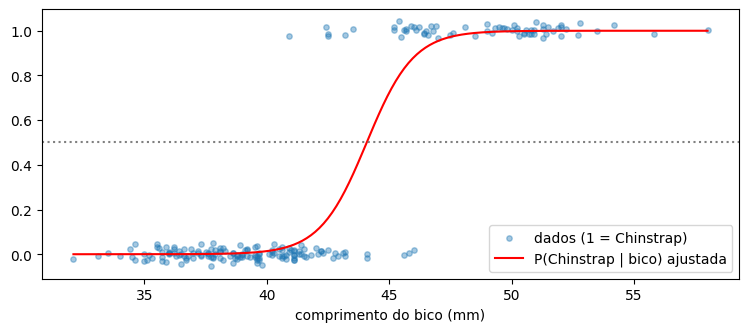

In [7]:
dois = pinguins[pinguins["species"].isin(["Adelie", "Chinstrap"])]   # isin: a linha está entre esses valores?
x_bico = dois["bill_length_mm"].to_numpy()
y_chin = (dois["species"] == "Chinstrap").astype(int).to_numpy()
x_centro = x_bico - x_bico.mean()   # centralizar o x ajuda o otimizador (os parâmetros ficam numa escala parecida)


def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def nll_logistica(parametros):
    a, b = parametros
    p = sigmoide(a + b * x_centro)
    p = np.clip(p, 1e-12, 1 - 1e-12)   # evita log(0)
    return -np.sum(y_chin * np.log(p) + (1 - y_chin) * np.log(1 - p))


a_log, b_log = minimize(nll_logistica, x0=[0, 0]).x
log_loss_mao = nll_logistica([a_log, b_log]) / len(y_chin)

# A logística do scikit-learn, sem regularização (penalty=None), deve chegar ao mesmo lugar.
modelo = LogisticRegression(penalty=None).fit(x_centro.reshape(-1, 1), y_chin)   # reshape: uma coluna
print(f"À mão:   a = {a_log:.4f}, b = {b_log:.4f}, log loss = {log_loss_mao:.4f}")
print(f"sklearn: a = {modelo.intercept_[0]:.4f}, b = {modelo.coef_[0, 0]:.4f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(x_bico, y_chin + rng.normal(0, 0.02, len(y_chin)), alpha=0.4, s=15, label="dados (1 = Chinstrap)")
eixo = np.linspace(x_bico.min(), x_bico.max(), 300)
ax.plot(eixo, sigmoide(a_log + b_log * (eixo - x_bico.mean())), color="red", label="P(Chinstrap | bico) ajustada")
ax.axhline(0.5, color="gray", linestyle=":")
ax.set_xlabel("comprimento do bico (mm)")
ax.legend()
plt.show()

**Conclusão:** a logística construída à mão (só com a sigmoide, a log-verossimilhança da Bernoulli e o otimizador) chega praticamente aos mesmos coeficientes do scikit-learn (a = −2,165 e b = 1,043; as diferenças aparecem só na quarta casa decimal, por causa da precisão de cada otimizador). A log loss média é **0,1175**.

No gráfico, a curva vermelha passa de "quase certamente Adelie" para "quase certamente Chinstrap" numa faixa estreita, cruzando 50% perto de **44,1 mm**. Os poucos Chinstrap com bico curto (à esquerda, em cima) e Adelie com bico longo (à direita, embaixo) são os casos em que o modelo erra. O coeficiente $b = 1{,}04$ significa que cada milímetro a mais de bico multiplica as **chances** de ser Chinstrap por $e^{1{,}04} \approx 2{,}8$, a mesma interpretação de coeficientes do notebook 02 do ML-02.

## 🎓 Conceito: comparando modelos com a verossimilhança (AIC)

A log-verossimilhança máxima também serve para **comparar modelos**: quanto maior, melhor o modelo explica os dados. Mas há uma armadilha: modelos com **mais parâmetros** sempre conseguem uma verossimilhança maior (é o **overfitting**). O **AIC** (critério de informação de Akaike) penaliza a complexidade:

$$\text{AIC} = 2k - 2\ell_{\max}$$

onde $k$ é o número de parâmetros. **Menor AIC é melhor.** Vamos usá-lo para decidir, de forma objetiva, entre a normal e a log-normal para as contas (a comparação visual do notebook 08).

In [8]:
contas = gorjetas["total_bill"].to_numpy()
candidatos = {
    "normal": (stats.norm, stats.norm.fit(contas)),
    "log-normal": (stats.lognorm, stats.lognorm.fit(contas, floc=0)),
    "gama": (stats.gamma, stats.gamma.fit(contas, floc=0)),
    "exponencial": (stats.expon, stats.expon.fit(contas, floc=0)),
}
linhas = []
for nome, (distribuicao, parametros) in candidatos.items():
    log_L = np.sum(distribuicao.logpdf(contas, *parametros))   # *parametros "abre" a tupla de parâmetros
    k = len(parametros) - 1   # o loc fixado em 0 (floc=0) não conta; na normal, loc é a própria média
    if nome == "normal":
        k = 2
    linhas.append({"distribuição": nome, "parâmetros livres": k, "log-verossimilhança": log_L, "AIC": 2 * k - 2 * log_L})
pd.DataFrame(linhas).set_index("distribuição").sort_values("AIC")

,parâmetros livres,log-verossimilhança,AIC
distribuição,,,
log-normal,2,-850.0122,1704.0244
gama,2,-852.1990,1708.3981
normal,2,-879.1826,1762.3652
exponencial,1,-972.3331,1946.6662


**Conclusão:** a **log-normal** tem o menor AIC (**1.704,0**), seguida de perto pela **gama** (1.708,4). A normal fica bem atrás (1.762,4), e a exponencial, com um único parâmetro, é a pior (1.946,7). Agora temos um número que confirma o que vimos nos gráficos do notebook 08: a log-normal descreve as contas bem melhor que a normal.

Como regra prática, diferenças de AIC menores que ~2 indicam modelos praticamente equivalentes, e diferenças acima de ~10 indicam uma preferência forte. Aqui, log-normal e gama estão próximas (4,4 pontos), e as duas são muito melhores que a normal (mais de 50 pontos).

## 2. Resumo e próximos passos

| Suposição sobre os dados | Máxima verossimilhança equivale a... | Onde aparece |
|---|---|---|
| Normal com média $\mu$ | média da amostra | estimar médias |
| $y$ normal em torno de $a + bx$ | **mínimos quadrados** (MSE) | regressão linear (ML-01) |
| $y$ Laplace em torno de $a + bx$ | mínimo erro absoluto (MAE) | regressão robusta |
| $y$ Bernoulli com $p = \text{sigmoide}(a + bx)$ | **log loss** | regressão logística (ML-02) |
| Contagens Poisson | média | regressão de Poisson |

**Conceitos que você aprendeu**
- **Verossimilhança**: a mesma fórmula da probabilidade, com os dados fixos e o parâmetro variando.
- **Log-verossimilhança** e por que usamos logs (estabilidade e somas).
- **EMV** da binomial, da normal (dividindo por $n$) e da Poisson, por fórmula e com um **otimizador numérico**.
- **Erros normais ⇒ mínimos quadrados**; **Bernoulli ⇒ log loss**.
- Uma **regressão logística construída à mão**, idêntica à do scikit-learn.
- O **AIC** para comparar modelos penalizando a complexidade.

**Python novo:** `scipy.optimize.minimize` (`x0`, `bounds`, `.x`, `.success`), `.logpdf` / `.logpmf`, `ax.clabel`, `np.polyfit`, `.isin`, `.reshape(-1, 1)`, `LogisticRegression(penalty=None)`, desempacotamento com `*`.

**Próximo notebook:** com isto fechamos a Parte III. Na **Parte IV**, vamos construir pontes diretas com o ML. O notebook 14 revisita a **regressão linear** do ponto de vista estatístico: coeficientes com **erros padrão e intervalos de confiança**, testes para cada coeficiente, o $R^2$ e a verificação das **premissas** com a análise de resíduos.